## ML Lab 8 SVM
### Name : Pranjal Chaubey
### Roll no: 1
### Batch  : A-A1

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')



In [4]:
import pandas as pd
df = pd.read_csv("/content/ai4i2020 - ai4i2020.csv")

In [5]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [7]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [8]:
df.shape

(10000, 14)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [10]:
df.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [11]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [12]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [16]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [17]:
df["Machine failure"].value_counts(normalize=True)*100

,proportion
Machine failure,
0,96.61
1,3.39


In [18]:
df["Process temperature [K]"].value_counts(normalize=True)*100

,proportion
Process temperature [K],
310.6,3.17
310.8,2.73
310.7,2.66
308.6,2.65
310.5,2.63
...,...
306.9,0.04
313.7,0.04
305.8,0.03


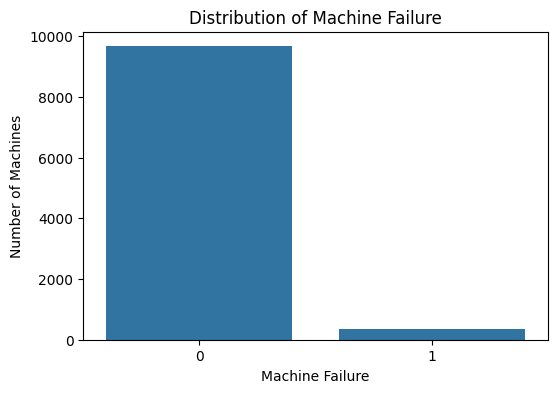

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.countplot(x="Machine failure",data=df)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Machines")
plt.show()

In [20]:
x = df.drop('Machine failure',axis=1)

In [21]:
# OR

In [22]:
y = df["Machine failure"]

In [23]:
print("Input shape: ",x.shape)
print("Output shape: ",y.shape)

Input shape:  (10000, 13)
Output shape:  (10000,)


In [24]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [25]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.20,random_state=42,stratify=y)
print("Training samples : ", x_train.shape[0])
print("Testing samples : ", x_test.shape[0])

Training samples :  8000
Testing samples :  2000


In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)

In [27]:
# Kernel-Linear

In [28]:
linear_svm = Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="linear"))]
)
linear_svm.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [29]:
y_pred_linear = linear_svm.predict(x_test)

In [30]:
accuracy_linear = accuracy_score(y_test,y_pred_linear)
precision_linear = precision_score(y_test,y_pred_linear,zero_division=0)
f1_linear = f1_score(y_test,y_pred_linear)
recall_linear = recall_score(y_test,y_pred_linear)
print("Accuracy: ",accuracy_linear)
print("Precision: ",precision_linear)
print("F1 Score: ",f1_linear)
print("Recall: ",recall_linear)

Accuracy:  0.966
Precision:  0.0
F1 Score:  0.0
Recall:  0.0


In [31]:
print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names=["No Failure","Failure"],
        zero_division=0
        )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



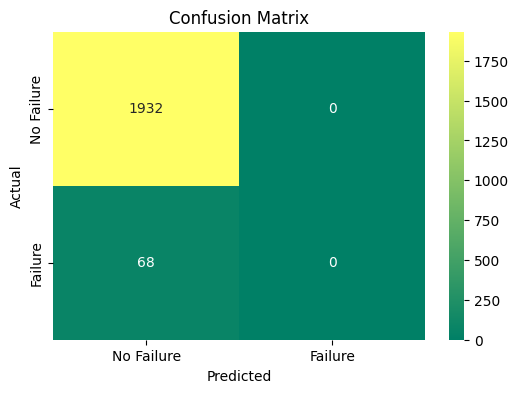

In [32]:
cm_linear = confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6,4))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="summer",
            xticklabels=["No Failure","Failure"],
            yticklabels=["No Failure","Failure"]
            )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

#

In [33]:
rbf_svm = Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="rbf"))]
)
rbf_svm.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [34]:
# RBF

In [35]:
y_pred_rbf = rbf_svm.predict(x_test)

In [36]:
accuracy_rbf = accuracy_score(y_test,y_pred_rbf)
precision_rbf = precision_score(y_test,y_pred_rbf,zero_division=0)
f1_rbf = f1_score(y_test,y_pred_rbf)
recall_rbf = recall_score(y_test,y_pred_rbf)
print("Accuracy: ",accuracy_rbf)
print("Precision: ",precision_rbf)
print("F1 Score: ",f1_rbf)
print("Recall: ",recall_rbf)

Accuracy:  0.972
Precision:  0.875
F1 Score:  0.3333333333333333
Recall:  0.20588235294117646


In [37]:
print(
    classification_report(
        y_test,
        y_pred_rbf,
        target_names=["No Failure","Failure"],
        zero_division=0
        )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



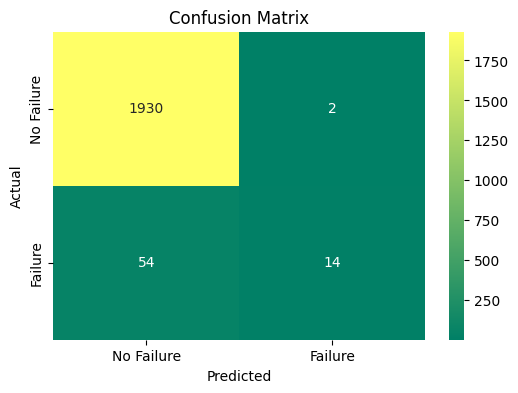

In [38]:
cm_rbf = confusion_matrix(y_test,y_pred_rbf)
plt.figure(figsize=(6,4))
sns.heatmap(cm_rbf,annot=True,fmt="d",cmap="summer",
            xticklabels=["No Failure","Failure"],
            yticklabels=["No Failure","Failure"]
            )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [39]:
# kernel sigmoid

Accuracy:  0.945
Precision:  0.15
F1 Score:  0.140625
Recall:  0.1323529411764706
              precision    recall  f1-score   support

  No Failure       0.97      0.97      0.97      1932
     Failure       0.15      0.13      0.14        68

    accuracy                           0.94      2000
   macro avg       0.56      0.55      0.56      2000
weighted avg       0.94      0.94      0.94      2000



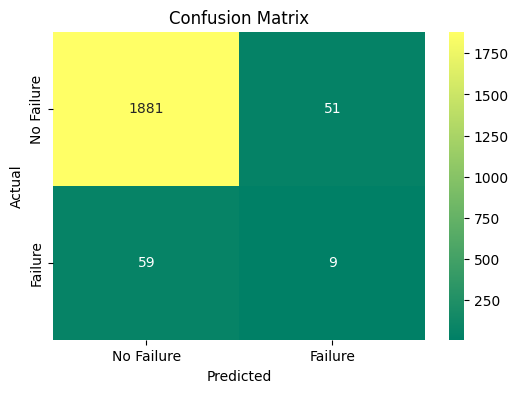

In [40]:
sigmoid_svm = Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="sigmoid"))]
)
sigmoid_svm.fit(x_train,y_train)


y_pred_sigmoid = sigmoid_svm.predict(x_test)


accuracy_sigmoid = accuracy_score(y_test,y_pred_sigmoid)
precision_sigmoid = precision_score(y_test,y_pred_sigmoid,zero_division=0)
f1_sigmoid = f1_score(y_test,y_pred_sigmoid)
recall_sigmoid = recall_score(y_test,y_pred_sigmoid)
print("Accuracy: ",accuracy_sigmoid)
print("Precision: ",precision_sigmoid)
print("F1 Score: ",f1_sigmoid)
print("Recall: ",recall_sigmoid)



print(
    classification_report(
        y_test,
        y_pred_sigmoid,
        target_names=["No Failure","Failure"],
        zero_division=0
        )
)


cm_sigmoid = confusion_matrix(y_test,y_pred_sigmoid)
plt.figure(figsize=(6,4))
sns.heatmap(cm_sigmoid,annot=True,fmt="d",cmap="summer",
            xticklabels=["No Failure","Failure"],
            yticklabels=["No Failure","Failure"]
            )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Accuracy:  0.9745
Precision:  0.8695652173913043
F1 Score:  0.43956043956043955
Recall:  0.29411764705882354
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.87      0.29      0.44        68

    accuracy                           0.97      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



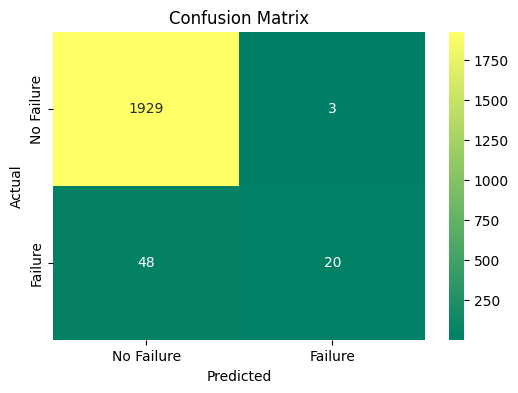

In [41]:
poly_svm = Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="poly"))]
)
poly_svm.fit(x_train,y_train)


y_pred_poly = poly_svm.predict(x_test)


accuracy_poly = accuracy_score(y_test,y_pred_poly)
precision_poly = precision_score(y_test,y_pred_poly,zero_division=0)
f1_poly = f1_score(y_test,y_pred_poly)
recall_poly = recall_score(y_test,y_pred_poly)
print("Accuracy: ",accuracy_poly)
print("Precision: ",precision_poly)
print("F1 Score: ",f1_poly)
print("Recall: ",recall_poly)



print(
    classification_report(
        y_test,
        y_pred_poly,
        target_names=["No Failure","Failure"],
        zero_division=0
        )
)


cm_poly = confusion_matrix(y_test,y_pred_poly)
plt.figure(figsize=(6,4))
sns.heatmap(cm_poly,annot=True,fmt="d",cmap="summer",
            xticklabels=["No Failure","Failure"],
            yticklabels=["No Failure","Failure"]
            )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [42]:
comparison = pd.DataFrame({
    "Model": ["Linear", "RBF", "Sigmoid", "Poly"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_sigmoid, accuracy_poly],
    "Precision": [precision_linear, precision_rbf, precision_sigmoid, precision_poly],
    "F1 Score": [f1_linear, f1_rbf, f1_sigmoid, f1_poly],
    "Recall": [recall_linear, recall_rbf, recall_sigmoid, recall_poly]
})
comparison

,Model,Accuracy,Precision,F1 Score,Recall
0,Linear,0.9660,0.000000,0.000000,0.000000
1,RBF,0.9720,0.875000,0.333333,0.205882
2,Sigmoid,0.9450,0.150000,0.140625,0.132353
3,Poly,0.9745,0.869565,0.439560,0.294118


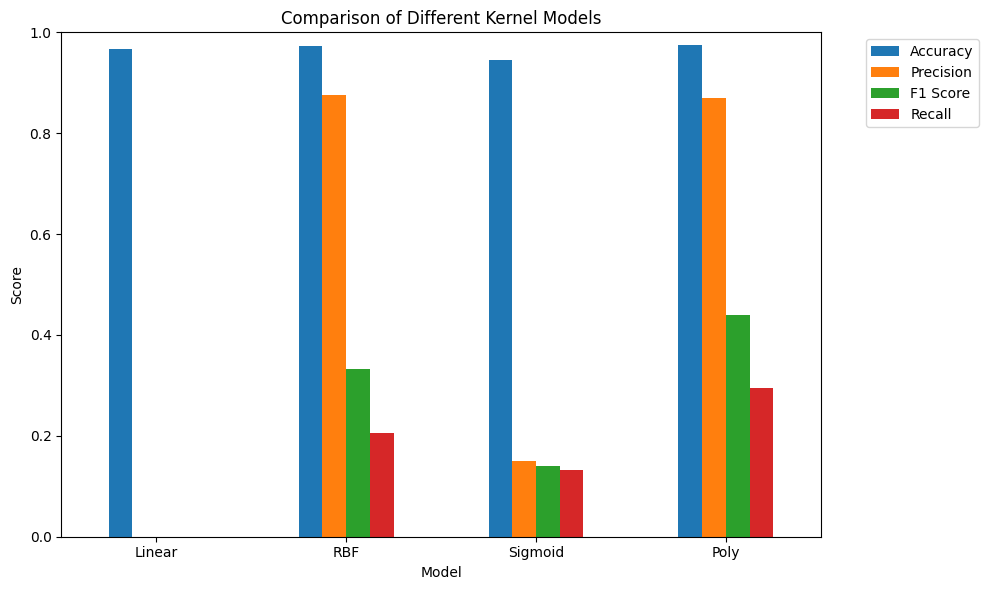

In [43]:
comparison_plot = comparison.set_index("Model")
comparison_plot.plot(kind="bar",figsize=(10,6))
plt.title("Comparison of Different Kernel Models")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1),loc="upper left")
plt.tight_layout()
plt.show()

In [44]:
param_grid = [{"classifier__kernel" : ["linear"],"classifier__c":[0.1,1,10,100]},
              {"classifier__kernel":["rbf"],"classifier__c":[0.1,1,10,100],"classifier__gamma":["scale",0.1,1,0.01]}]

In [45]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(estimator=linear_svm, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1, verbose=1)

In [46]:
param_grid = [
    {"classifier__kernel": ["linear"], "classifier__C": [0.1, 1, 10, 100]},
    {"classifier__kernel": ["rbf"], "classifier__C": [0.1, 1, 10, 100], "classifier__gamma": ["scale", 0.1, 1, 0.01]}
]

grid_search.param_grid = param_grid
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type'])])),
                                       ('classifier', SVC(kernel='linear'))]),
             n_jobs=-1,
             param_grid=[{'classifier__C': [0.1, 1, 10, 100],
                          'classifier__kernel': ['linear']},
                         {'classifier__C': [0.1, 1, 10, 100],
                          'classifier__gamma': ['scale', 0.1, 1, 0.01],
                          'classifier__kernel': ['rbf']}],
             scoring='f1', verbose=1)

In [50]:
print(grid_search.best_params_)

{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [52]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(x_test)


accuracy_tuned = accuracy_score(y_test,y_pred_tuned)
precision_tuned = precision_score(y_test,y_pred_tuned,zero_division=0)
f1_tuned = f1_score(y_test,y_pred_tuned)
recall_tuned = recall_score(y_test,y_pred_tuned)

print("Accuracy: ",accuracy_tuned)
print("Precision: ",precision_tuned)
print("F1 Score: ",f1_tuned)
print("Recall: ",recall_tuned)

Accuracy:  0.98
Precision:  0.7592592592592593
F1 Score:  0.6721311475409836
Recall:  0.6029411764705882
